# 17. 실험 7 — 변화량에 쓸 수 있나: 같은 숲, 다른 해 사진이면 탄소가 얼마나 흔들리나

**질문:** 처음 보는 지역에서, **숲이 그대로인 곳**을 2022–23년 사진과 2024–25년 사진으로 각각 계산하면 탄소가 몇 % 다르게 나오나. 숲이 안 변했으니 차이는 전부 **"가짜 변화"**다.

**쉬운 설명 (체중계 비유)**
- 변화량 = 올해 몸무게 − 작년 몸무게. 체중계가 **매번 똑같이** 1kg 더 나오면 빼기에서 사라져서 문제없다
- 문제는 체중계가 **잴 때마다 다르게** 틀릴 때. 가짜 변화가 실제 1년 변화보다 크면 변화량을 못 믿는다
- 그래서 "오차가 해마다 일정한가" = "두 시기 오차의 차이가 작은가"를 본다

**방법**
- 모델: **v1**(05와 똑같이 다시 학습 — 같은 난수·같은 표본이라 09와 같은 모델. 첫 폴드에서 검산). 계절 모델(13a)은 2022–23 계절 데이터가 없어 이번엔 제외
- 같은 모델로 평가 지역의 2024–25 피처와 2022–23 피처를 각각 예측
- 평가 픽셀: 두 시기 모두 사진 값이 있고, **2022년 이후 산림손실(Hansen)이 없는** 픽셀
- 정답: 2024+ 임상도를 두 시기 공통 정답으로 둠 (숲이 그대로라는 가정)

**한계 (미리 적어 둠):** Hansen은 벌채·산불 같은 큰 손실만 잡고 솎아베기·조림·2025년 손실은 못 거른다. 그리고 지금 탄소 계산(면적 × 고정 계수)은 **나무가 자라는 것은 보지 못한다** → 이 실험은 "매년 숲 종류별 면적(활동자료)을 위성으로 낼 때 얼마나 흔들리나"를 보는 것

**끊겨도 이어서:** 폴드마다 저장 → **모두 실행** 다시 하면 남은 폴드만. 시간 약 2–2.5시간 [추정]

**순서:** [1] 설정 → [2] 데이터 → [3] 사전 기록 → [4] LORO 40폴드 → [5] 모으기 → [6] 결과·판정 → [7] 그림

In [1]:
# [1] 설정 — 05와 같은 값
import os, json, time, gc, warnings
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt
from google.colab import drive
warnings.filterwarnings('ignore', category=RuntimeWarning)

drive.mount('/content/drive')
OUT      = '/content/drive/MyDrive/forest/outputs'
V1_REF   = f'{OUT}/exp4c_folds'       # 09 v1 결과 (재현 검산용)
FOLD_DIR = f'{OUT}/exp7_folds'
os.makedirs(FOLD_DIR, exist_ok=True)

TRAIN_REGIONS = ['inje', 'hongcheon', 'gangneung', 'pyeongchang',
                 'bonghwa', 'geumsan', 'geochang', 'suncheon']
KR = {'inje': '인제', 'hongcheon': '홍천', 'gangneung': '강릉', 'pyeongchang': '평창',
      'bonghwa': '봉화', 'geumsan': '금산', 'geochang': '거창', 'suncheon': '순천'}
C    = {1: 79.25, 2: 101.02, 3: 92.01}
CVEC = np.array([C[1], C[2], C[3]])
SEEDS              = [16, 17, 18, 19, 20]
N_TRAIN_PER_REGION = 30_000
RF_PARAMS = dict(n_estimators=80, min_samples_leaf=20, max_features='sqrt',
                 class_weight='balanced', n_jobs=-1)
LOSS_FROM = 22                       # Hansen lossyear ≥ 22 (2022년 이후 손실) 픽셀 제외

# 기준 [유도, 54-1]: 고려대 논문 수치로 전국 순 저장량 변화 연 0.56–0.99%
YEAR_CHANGE = 0.56
print('준비 완료')

Mounted at /content/drive
준비 완료


In [2]:
# [2] 데이터 — v1 캐시(2024–25) + 과거 캐시(2022–23)
S, O = {}, {}
rows = []
for r in TRAIN_REGIONS:
    z = np.load(f'{OUT}/{r}_s05.npz'); S[r] = dict(X=z['X'], y=z['y'], n_total=int(z['n_total']))
    o = np.load(f'{OUT}/{r}_old.npz')
    assert len(o['y']) == len(S[r]['y']) and (o['y'] == S[r]['y']).all(), f'{r}: 과거 캐시 픽셀이 v1과 다름'
    E = o['ok'] & (o['loss'] < LOSS_FROM)
    O[r] = dict(X=o['X'], E=E)
    rows.append(dict(지역=KR[r], 표본=len(o['y']), 과거값있음=f'{o["ok"].mean()*100:.1f}%',
                     손실제외=f'{(o["loss"] >= LOSS_FROM).mean()*100:.2f}%', 평가픽셀=f'{E.mean()*100:.1f}%'))
print(pd.DataFrame(rows).to_string(index=False))
print('\n평가픽셀 = 두 시기 모두 값 있음 & 2022년 이후 산림손실 없음')

지역     표본  과거값있음  손실제외  평가픽셀
인제 600263 100.0% 0.89% 99.1%
홍천 599525 100.0% 1.65% 98.3%
강릉 600079 100.0% 0.85% 99.2%
평창 600530 100.0% 1.94% 98.1%
봉화 599540 100.0% 0.93% 99.1%
금산 600247 100.0% 3.76% 96.2%
거창 601114 100.0% 3.24% 96.8%
순천 600845 100.0% 1.27% 98.7%

평가픽셀 = 두 시기 모두 값 있음 & 2022년 이후 산림손실 없음


In [3]:
# [3] 사전 기록 — 처음 실행할 때 exp7_prereg.json 저장 (이후 덮어쓰지 않음)
CONFIRMED = True
PREREG = {
    'date': time.strftime('%Y-%m-%d %H:%M'),
    'question': '처음 보는 지역에서, 숲이 그대로인 픽셀을 2022–23 사진과 2024–25 사진으로 계산한 탄소가 얼마나 다른가 (가짜 변화)',
    'model': 'v1 38피처, 05와 같은 LORO 학습(같은 난수·표본, random_state=seed). 09 carb0와 재현 검산',
    'images': '2024–25 = 기존 v1 / 2022–23 = 16번(기간만 다르고 나머지 동일, 피처 코드 검산 통과)',
    'eval': '두 시기 모두 값 있음 & Hansen lossyear ≥ 22 아님. 정답 = 2024+ 임상도(두 시기 공통)',
    'measure': 'Δ = 오차(2024–25) − 오차(2022–23), %p. 정답이 같으므로 Δ = 예측 탄소의 연도 간 차이 ÷ 정답 탄소',
    'rule': ('딱 자르기 기준: 5/5 시드에서 지역 |Δ| 평균 < 0.5%p AND 8곳 모두 |Δ| < 1.0%p '
             '→ "이 조건에서 연도 간 흔들림이 1년치 실제 변화보다 작다"'),
    'basis': ('전국 순 저장량 변화 연 0.56–0.99% [유도, 고려대 논문 수치]. 가짜 변화가 1년치 변화보다 작아야 변화량을 읽을 수 있음. '
              '05 기준 2.5%(임목축적 증가율, 원문 미확인)는 참고로 함께 출력. '
              '숲 종류 면적 변화만 보는 용도라면 실제 변화가 더 작아(연 1% 미만 [추정]) 더 엄격한 기준이 필요'),
    'record': ['확률 섞기 Δ (같은 규칙으로 계산, 기록)', '두 시기 오차의 지역 순위 일치(Spearman, 시드별)',
               '픽셀 예측이 바뀐 비율', '침엽·활엽·혼효 예측 비율의 연도 간 차이', '면적가중 합산 Δ'],
    'prediction': ['[추정] 지역 오차 순서는 두 시기에 거의 같음 (시드별 Spearman ≥ 0.8)',
                   '[추정] 지역 |Δ| 평균 0.3–0.8%p, 규칙 통과는 반반'],
    'limits': ['Hansen은 큰 손실만 잡음 — 솎아베기·조림·2025년 손실은 못 거름',
               '면적 × 고정 계수 방식이라 생장은 못 봄 → 활동자료(숲 종류 면적)의 안정성을 보는 실험',
               '시기 2개뿐 — 흔들림인지 한 방향으로 움직이는지 구별 못 함'],
    'seeds': SEEDS, 'carbon_coeff': C,
}
pr = f'{OUT}/exp7_prereg.json'
if os.path.exists(pr):
    print('저장된 사전 기록 (덮어쓰지 않음):\n'); print(json.dumps(json.load(open(pr, encoding='utf-8')), ensure_ascii=False, indent=1))
elif CONFIRMED:
    json.dump(PREREG, open(pr, 'w', encoding='utf-8'), ensure_ascii=False, indent=1); print('사전 기록 저장:', pr)

사전 기록 저장: /content/drive/MyDrive/forest/outputs/exp7_prereg.json


In [4]:
# [4] LORO 40폴드 — 폴드마다 저장. 끊기면 "모두 실행"
assert os.path.exists(f'{OUT}/exp7_prereg.json'), '[3] 먼저'

def csum(y): return float(sum((y == v).sum() * C[v] for v in (1, 2, 3)))

def metrics(y, P):
    h = P.argmax(1) + 1
    t = csum(y)
    return dict(eh=(csum(h) - t) * 100 / t, es=(float((P @ CVEC).sum()) - t) * 100 / t,
                pch=csum(h), pcs=float((P @ CVEC).sum()),
                share=np.array([(h == v).mean() for v in (1, 2, 3)]), h=h)

folds = [(s, r) for s in SEEDS for r in TRAIN_REGIONS]
todo  = [(s, r) for s, r in folds if not os.path.exists(f'{FOLD_DIR}/s{s}_{r}.npz')]
print(f'전체 {len(folds)}폴드 중 완료 {len(folds) - len(todo)}, 남은 {len(todo)}\n')

times = []
for k, (seed, test) in enumerate(todo, 1):
    t0 = time.time()
    rng = np.random.default_rng(seed)                  # 05 [7]과 같은 순서·같은 난수
    Xtr, ytr = [], []
    for r in TRAIN_REGIONS:
        if r == test: continue
        n = len(S[r]['y'])
        i = rng.choice(n, size=min(N_TRAIN_PER_REGION, n), replace=False)
        Xtr.append(S[r]['X'][i]); ytr.append(S[r]['y'][i])
    Xtr, ytr = np.concatenate(Xtr), np.concatenate(ytr)
    clf = RandomForestClassifier(random_state=seed, **RF_PARAMS)
    clf.fit(Xtr, ytr); del Xtr, ytr; gc.collect()
    assert list(clf.classes_) == [1, 2, 3]

    y = S[test]['y']
    Pn_full = clf.predict_proba(S[test]['X'])
    # 재현 검산: 전체 표본 딱 자르기 오차 = 09 carb0
    e_full = (csum(Pn_full.argmax(1) + 1) - csum(y)) * 100 / csum(y)
    ref = float(np.load(f'{V1_REF}/s{seed}_{test}.npz')['carb0'])
    assert abs(e_full - ref) < 0.01, f's{seed} {test}: 05/09 모델 재현 실패 {e_full:.3f} vs {ref:.3f} — 멈추고 보고'

    E = O[test]['E']
    Pn = Pn_full[E]
    Po = clf.predict_proba(O[test]['X'][E])
    del clf, Pn_full; gc.collect()
    mn, mo = metrics(y[E], Pn), metrics(y[E], Po)
    out = dict(t_c=csum(y[E]), n_eval=int(E.sum()), n_total=S[test]['n_total'],
               flip=float((mn['h'] != mo['h']).mean()))
    for tag, m in (('new', mn), ('old', mo)):
        for key in ('eh', 'es', 'pch', 'pcs', 'share'):
            out[f'{tag}_{key}'] = m[key]
    np.savez(f'{FOLD_DIR}/s{seed}_{test}.npz', **out)

    dt = time.time() - t0; times.append(dt)
    eta = np.mean(times) * (len(todo) - k) / 60
    print(f'[{k:2d}/{len(todo)}] s{seed} {KR[test]:3s}  오차 2024–25 {mn["eh"]:+5.2f} / 2022–23 {mo["eh"]:+5.2f}  '
          f'Δ {mn["eh"] - mo["eh"]:+5.2f}%p (확률 {mn["es"] - mo["es"]:+5.2f})  바뀐 픽셀 {out["flip"]*100:4.1f}%  '
          f'{dt:4.0f}초  남은 약 {eta:.0f}분')
print('\n모든 폴드 완료')

전체 40폴드 중 완료 0, 남은 40

[ 1/40] s16 인제   오차 2024–25 +2.45 / 2022–23 -0.55  Δ +3.01%p (확률 +1.92)  바뀐 픽셀 21.0%   145초  남은 약 94분
[ 2/40] s16 홍천   오차 2024–25 +0.78 / 2022–23 -1.16  Δ +1.95%p (확률 +1.03)  바뀐 픽셀 18.2%   145초  남은 약 92분
[ 3/40] s16 강릉   오차 2024–25 -0.47 / 2022–23 -0.63  Δ +0.16%p (확률 -0.07)  바뀐 픽셀 11.9%   143초  남은 약 89분
[ 4/40] s16 평창   오차 2024–25 +2.31 / 2022–23 +2.37  Δ -0.07%p (확률 -0.22)  바뀐 픽셀 11.0%   141초  남은 약 86분
[ 5/40] s16 봉화   오차 2024–25 +1.23 / 2022–23 +0.70  Δ +0.53%p (확률 +0.23)  바뀐 픽셀 14.6%   143초  남은 약 84분
[ 6/40] s16 금산   오차 2024–25 +2.26 / 2022–23 +0.76  Δ +1.50%p (확률 +1.11)  바뀐 픽셀 17.2%   141초  남은 약 81분
[ 7/40] s16 거창   오차 2024–25 +0.37 / 2022–23 -1.00  Δ +1.37%p (확률 +0.78)  바뀐 픽셀 15.1%   140초  남은 약 78분
[ 8/40] s16 순천   오차 2024–25 -1.40 / 2022–23 -2.93  Δ +1.54%p (확률 +0.97)  바뀐 픽셀 19.0%   142초  남은 약 76분
[ 9/40] s17 인제   오차 2024–25 +2.41 / 2022–23 -0.50  Δ +2.92%p (확률 +1.90)  바뀐 픽셀 20.5%   146초  남은 약 74분
[10/40] s17 홍천   오차 2024–25 +0.83 / 2022–23 -1.15  Δ +1.97%

In [5]:
# [5] 모으기 → exp7_results.npz
ns, nr = len(SEEDS), len(TRAIN_REGIONS)
KEYS = ['t_c', 'n_eval', 'n_total', 'flip', 'new_eh', 'old_eh', 'new_es', 'old_es', 'new_pch', 'old_pch', 'new_pcs', 'old_pcs']
R = {k: np.full((ns, nr), np.nan) for k in KEYS}
SH = {t: np.full((ns, nr, 3), np.nan) for t in ('new', 'old')}
for i, s in enumerate(SEEDS):
    for j, r in enumerate(TRAIN_REGIONS):
        f = f'{FOLD_DIR}/s{s}_{r}.npz'
        if not os.path.exists(f): continue
        z = np.load(f)
        for k in KEYS: R[k][i, j] = float(z[k])
        for t in SH: SH[t][i, j] = z[f'{t}_share']
assert not np.isnan(R['t_c']).any(), '미완료 폴드 있음 — [4] 다시 실행'
R['dh'] = R['new_eh'] - R['old_eh']; R['ds'] = R['new_es'] - R['old_es']
np.savez(f'{OUT}/exp7_results.npz', **R, share_new=SH['new'], share_old=SH['old'],
         seeds=np.array(SEEDS), regions=np.array(TRAIN_REGIONS))
print('저장:', f'{OUT}/exp7_results.npz')

저장: /content/drive/MyDrive/forest/outputs/exp7_results.npz


In [6]:
# [6] 결과 · 판정
tab = pd.DataFrame({
    '지역': [KR[r] for r in TRAIN_REGIONS],
    '오차 2024–25': R['new_eh'].mean(0), '오차 2022–23': R['old_eh'].mean(0),
    'Δ(가짜변화)': R['dh'].mean(0), 'Δ 시드sd': R['dh'].std(0, ddof=1),
    'Δ 확률': R['ds'].mean(0),
    '바뀐 픽셀%': R['flip'].mean(0) * 100,
    '침엽 예측% 25→23': [f'{SH["new"][:, j, 0].mean()*100:.1f}→{SH["old"][:, j, 0].mean()*100:.1f}' for j in range(nr)],
})
tab.to_csv(f'{OUT}/exp7_by_region.csv', index=False)
print(tab.round(2).to_string(index=False))
print('(% / %p, 5시드 평균. Δ = 숲이 그대로인데 생긴 차이 → 0에 가까울수록 좋음)\n')

def judge(Dm, name):
    a = np.abs(Dm)
    m, mx = a.mean(1), a.max(1)
    ok = (m < 0.5) & (mx < 1.0)
    print(f'[{name}]')
    print('  시드별 지역 |Δ| 평균  ' + ' '.join(f'{x:.2f}' for x in m) + '   (기준 < 0.5)')
    print('  시드별 지역 |Δ| 최대  ' + ' '.join(f'{x:.2f}' for x in mx) + '   (기준 < 1.0)')
    res = bool(ok.all())
    print(f'  → {int(ok.sum())}/5 시드 충족 → {"통과" if res else "실패"}')
    return res

PASS_H = judge(R['dh'], '주 판정 · 딱 자르기')
PASS_S = judge(R['ds'], '기록 · 확률 섞기')

NT = R['n_total'][0]
dens = lambda pc: pc / R['n_eval']
tot_t = (dens(R['t_c']) * NT).sum(1)
agg = lambda pc: ((dens(pc) * NT).sum(1) - tot_t) * 100 / tot_t
dA = agg(R['new_pch']) - agg(R['old_pch'])
rho = [spearmanr(R['new_eh'][i], R['old_eh'][i]).correlation for i in range(ns)]
mean_abs = np.abs(R['dh']).mean()
print(f'\n8곳 합산 Δ (면적가중): {dA.mean():+.2f} ± {dA.std(ddof=1):.2f} %p')
print(f'두 시기 오차의 지역 순위 일치 (Spearman, 시드별): ' + ' '.join(f'{x:.2f}' for x in rho))
print(f'\n쉽게: 지역 하나의 가짜 변화는 평균 {mean_abs:.2f}%p — 1년치 실제 변화(전국 약 {YEAR_CHANGE}–0.99%)의 '
      f'{mean_abs/0.99:.1f}–{mean_abs/YEAR_CHANGE:.1f}배. (참고: 05 기준 2.5%와 비교하면 {mean_abs/2.5:.2f}배)')
print(f'예측: 순위 일치 ≥ 0.8 → {"맞음" if min(rho) >= 0.8 else "틀림"} / |Δ| 평균 0.3–0.8 → {"맞음" if 0.3 <= mean_abs <= 0.8 else "틀림"}')
json.dump(dict(pass_hard=PASS_H, pass_soft=PASS_S, mean_abs_delta=float(mean_abs), date=time.strftime('%Y-%m-%d %H:%M')),
          open(f'{OUT}/exp7_judgement.json', 'w'), ensure_ascii=False, indent=1)

지역  오차 2024–25  오차 2022–23  Δ(가짜변화)  Δ 시드sd  Δ 확률  바뀐 픽셀% 침엽 예측% 25→23
인제        2.42       -0.54     2.96    0.06  1.90   20.74    33.8→48.0
홍천        0.84       -1.11     1.95    0.02  1.04   18.19    32.7→42.8
강릉       -0.46       -0.59     0.13    0.03 -0.12   11.94    38.6→39.6
평창        2.39        2.45    -0.06    0.02 -0.24   10.82    32.6→32.9
봉화        1.26        0.71     0.55    0.05  0.26   14.75    52.4→54.7
금산        2.25        0.70     1.55    0.07  1.13   17.44    19.0→27.4
거창        0.43       -1.01     1.44    0.06  0.79   15.50    51.4→56.7
순천       -1.34       -2.95     1.61    0.07  0.97   19.31    47.4→55.7
(% / %p, 5시드 평균. Δ = 숲이 그대로인데 생긴 차이 → 0에 가까울수록 좋음)

[주 판정 · 딱 자르기]
  시드별 지역 |Δ| 평균  1.27 1.28 1.27 1.31 1.28   (기준 < 0.5)
  시드별 지역 |Δ| 최대  3.01 2.92 2.99 3.01 2.87   (기준 < 1.0)
  → 0/5 시드 충족 → 실패
[기록 · 확률 섞기]
  시드별 지역 |Δ| 평균  0.79 0.80 0.81 0.82 0.81   (기준 < 0.5)
  시드별 지역 |Δ| 최대  1.92 1.90 1.92 1.90 1.85   (기준 < 1.0)
  → 0/5 시드 충족 → 실패

8곳 합산 Δ (면적가중): +1.27 

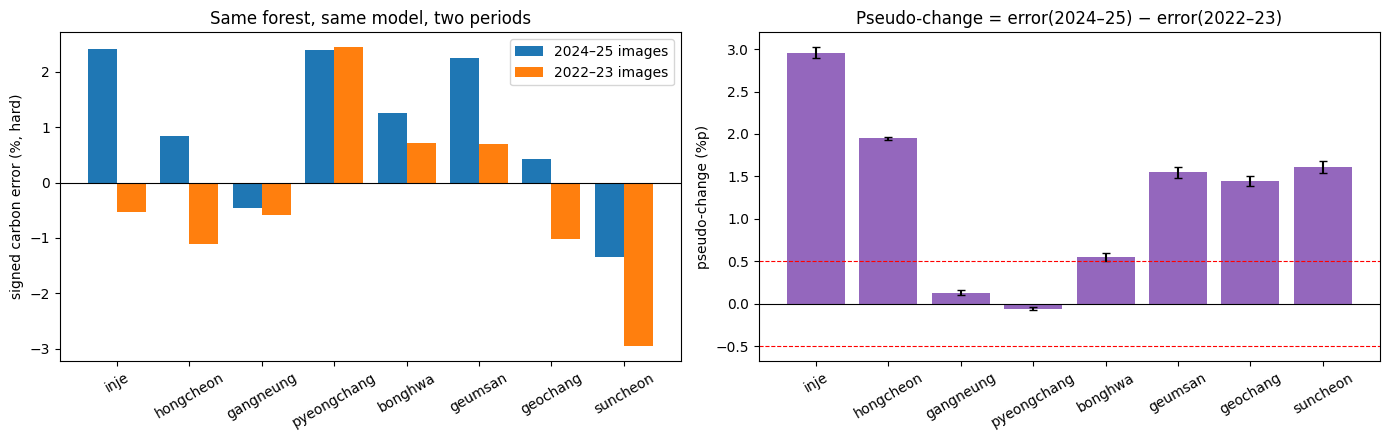

→ [2]·[6] 출력을 채팅에 붙여넣기


In [7]:
# [7] 그림 → exp7.png
x = np.arange(nr)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].bar(x - .2, R['new_eh'].mean(0), width=.4, color='tab:blue', label='2024–25 images')
ax[0].bar(x + .2, R['old_eh'].mean(0), width=.4, color='tab:orange', label='2022–23 images')
ax[0].axhline(0, c='k', lw=.8); ax[0].legend()
ax[0].set_xticks(x); ax[0].set_xticklabels(TRAIN_REGIONS, rotation=30)
ax[0].set_ylabel('signed carbon error (%, hard)'); ax[0].set_title('Same forest, same model, two periods')
ax[1].bar(x, R['dh'].mean(0), yerr=R['dh'].std(0, ddof=1), capsize=3, color='tab:purple')
for v in (0.5, -0.5): ax[1].axhline(v, c='r', ls='--', lw=.8)
ax[1].axhline(0, c='k', lw=.8)
ax[1].set_xticks(x); ax[1].set_xticklabels(TRAIN_REGIONS, rotation=30)
ax[1].set_ylabel('pseudo-change (%p)'); ax[1].set_title('Pseudo-change = error(2024–25) − error(2022–23)')
plt.tight_layout(); plt.savefig(f'{OUT}/exp7.png', dpi=150); plt.show()
print('→ [2]·[6] 출력을 채팅에 붙여넣기')